# Lab 2: Applications of eigenvectors

## Student: Zakhar Ambroziak

## Task 0: importing all required modules

In [2]:
import numpy as np
from matplotlib.image import imread
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt






## Task 1: Computing eigenvalues and eigenvectors of a matrix
To do this task, I have used built in function in NumPy called linalg.eig that returns eigenvalues and eigenvectors. After that I have removed imaginary parts for them using np.real. After that I checked whether the calculations made by NumPy are correct: I created simple for-loop that calculated Av for the left-hand side and λv for the right-hand side and compared both values with np.allclose.

In [ ]:
def task1(matrix: np.ndarray):
    values, vectors = np.linalg.eig(matrix)

    values, vectors = np.real(values), np.real(vectors)

    print("Results:\n")
    print("Matrix:")
    print(matrix)
    print("\neigenvalues:")
    print(*[f"λ{i}={values[i]}\n" for i in range(len(values))])
    print("eigenvectors:")
    print("\n".join([f"v{i}={vectors[:, i]}" for i in range(len(vectors))]))

    for i in range(len(values)):
        print(f"\nCheck #{i+1}")
    
        value = values[i]
        vector = vectors[:, i]
        print(f"λ={value}, vector={vector}")

        lhs = matrix @ vector
        rhs = value*vector

        print(f"{lhs} = {rhs} {'✅' if np.allclose(lhs, rhs) else '❌'}")

    return values, vectors

matrix = np.array([[1, 2], [3, 4]])
task1(matrix)



Results:

Matrix:
[[1 2]
 [3 4]]

eigenvalues:
λ0=-0.3722813232690143
 λ1=5.372281323269014

eigenvectors:
v0=[-0.82456484  0.56576746]
v1=[-0.41597356 -0.90937671]

Check #1
λ=-0.3722813232690143, vector=[-0.82456484  0.56576746]
[ 0.30697009 -0.21062466] = [ 0.30697009 -0.21062466] ✅

Check #2
λ=5.372281323269014, vector=[-0.41597356 -0.90937671]
[-2.23472698 -4.88542751] = [-2.23472698 -4.88542751] ✅


(array([-0.37228132,  5.37228132]),
 array([[-0.82456484, -0.41597356],
        [ 0.56576746, -0.90937671]]))

## Task 2: Implementation of Image Dimensionality Reduction using PCA

For this task I created one big function called task2 divided into 4 part with the comment sections. First two parts were provided in the lab file so I simply copied code from there and visualized a black-white image of NYC. In the part three I used PCA. At first, I trained it on our black-white image, as the result it counted variance matrix of the pixels and found eigenvectors and eigenvalues. After that we take cumulative sum of this variance ratios and finding the minimum number of components needed to get at least 95% of cumulative variance. After that we apply our results to the image. In the fourth part we compare different amount of the components for the image and seeing that when we have less of them - we lose too much information and it gets blurry. And when we take larger number of components, we get a sharper image because it gives us sharper visual details.

(1067, 1600, 3)


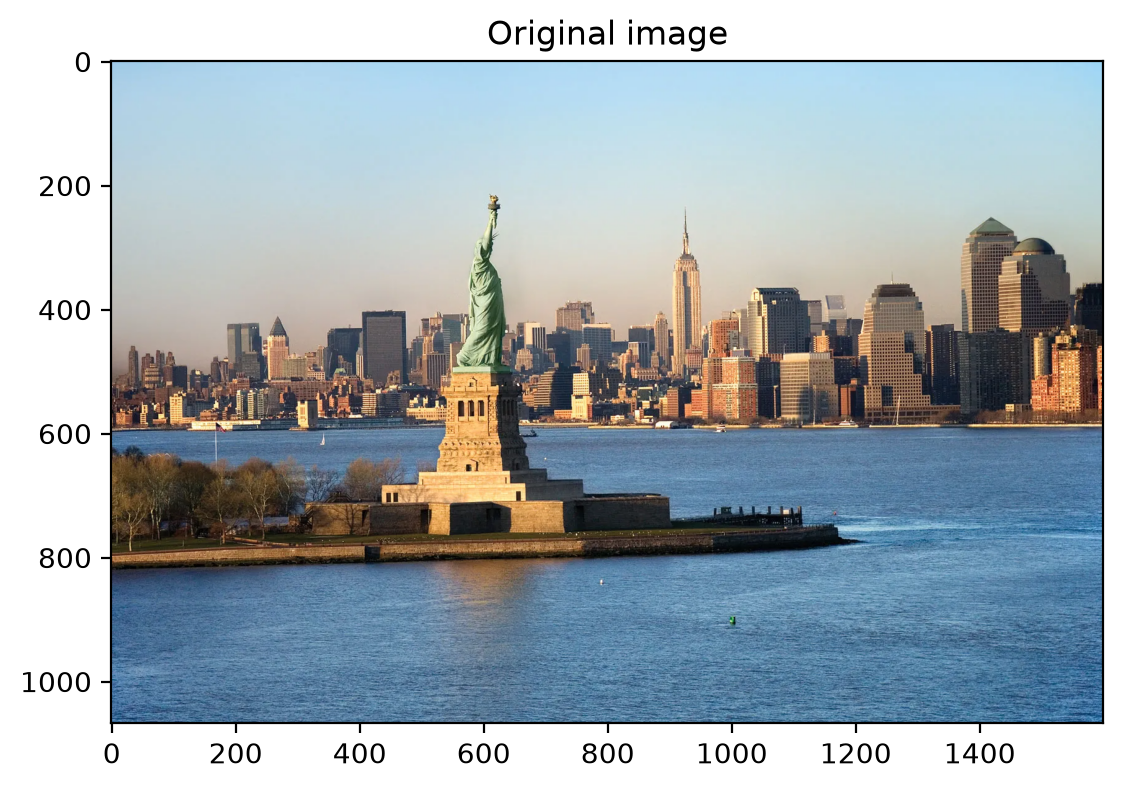

(1067, 1600)
1.0


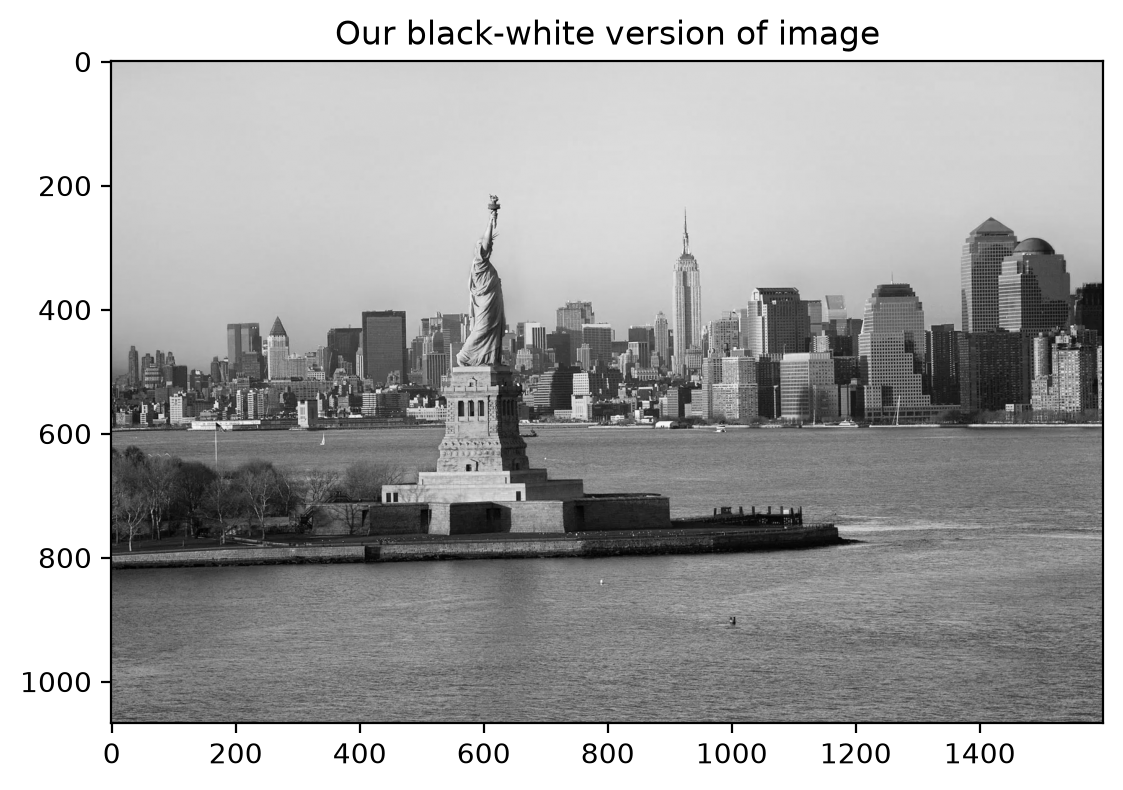

40


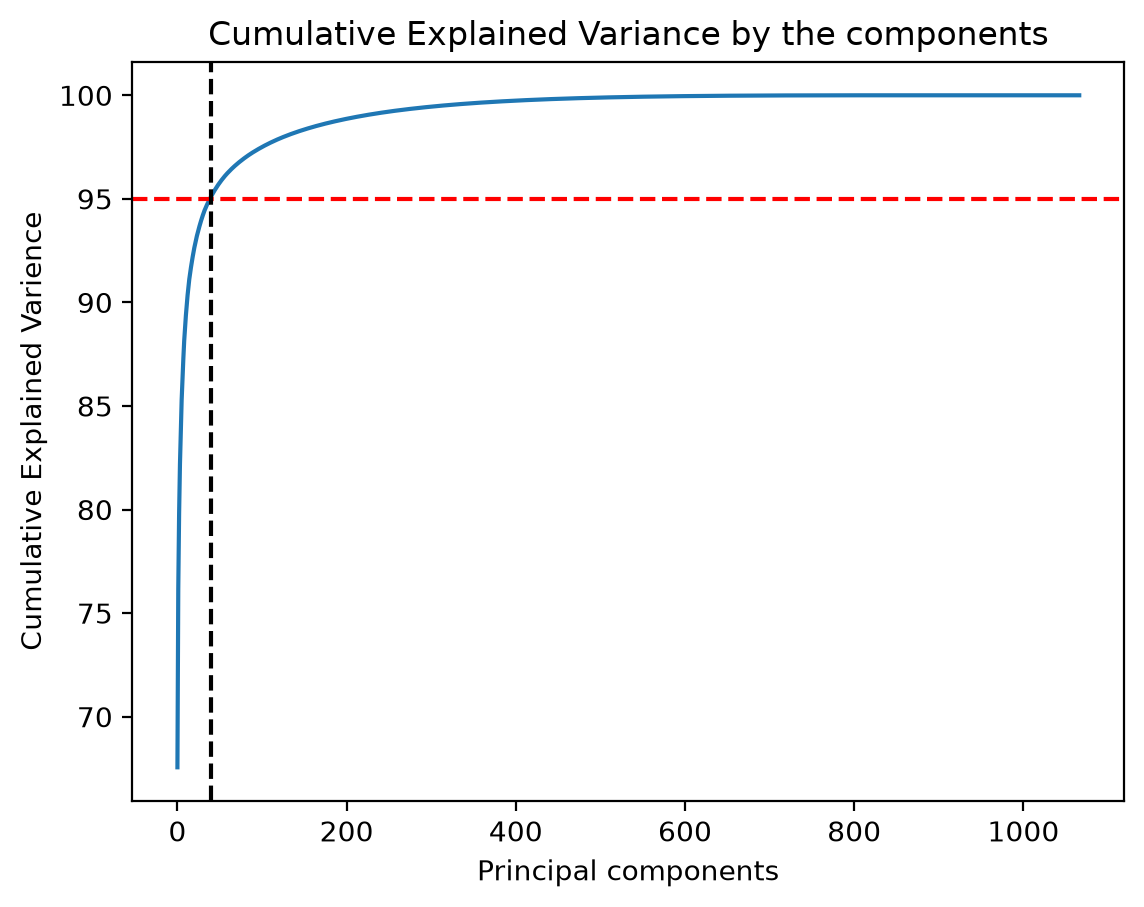

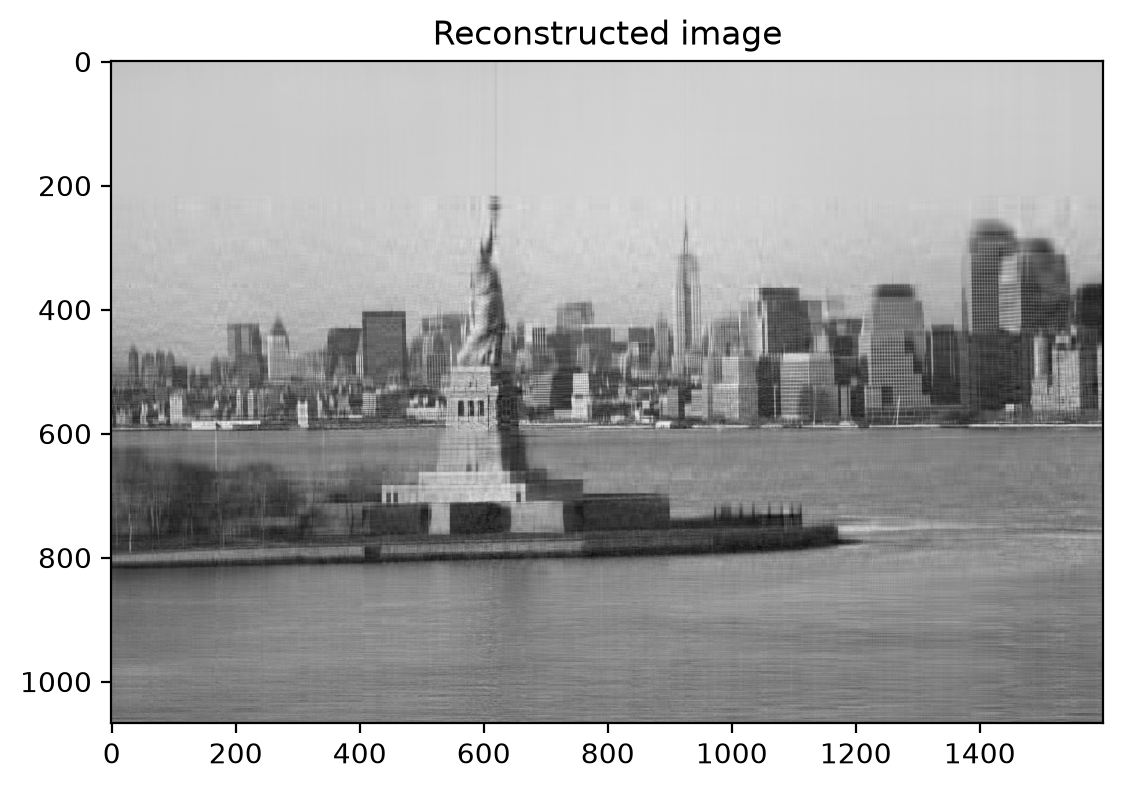

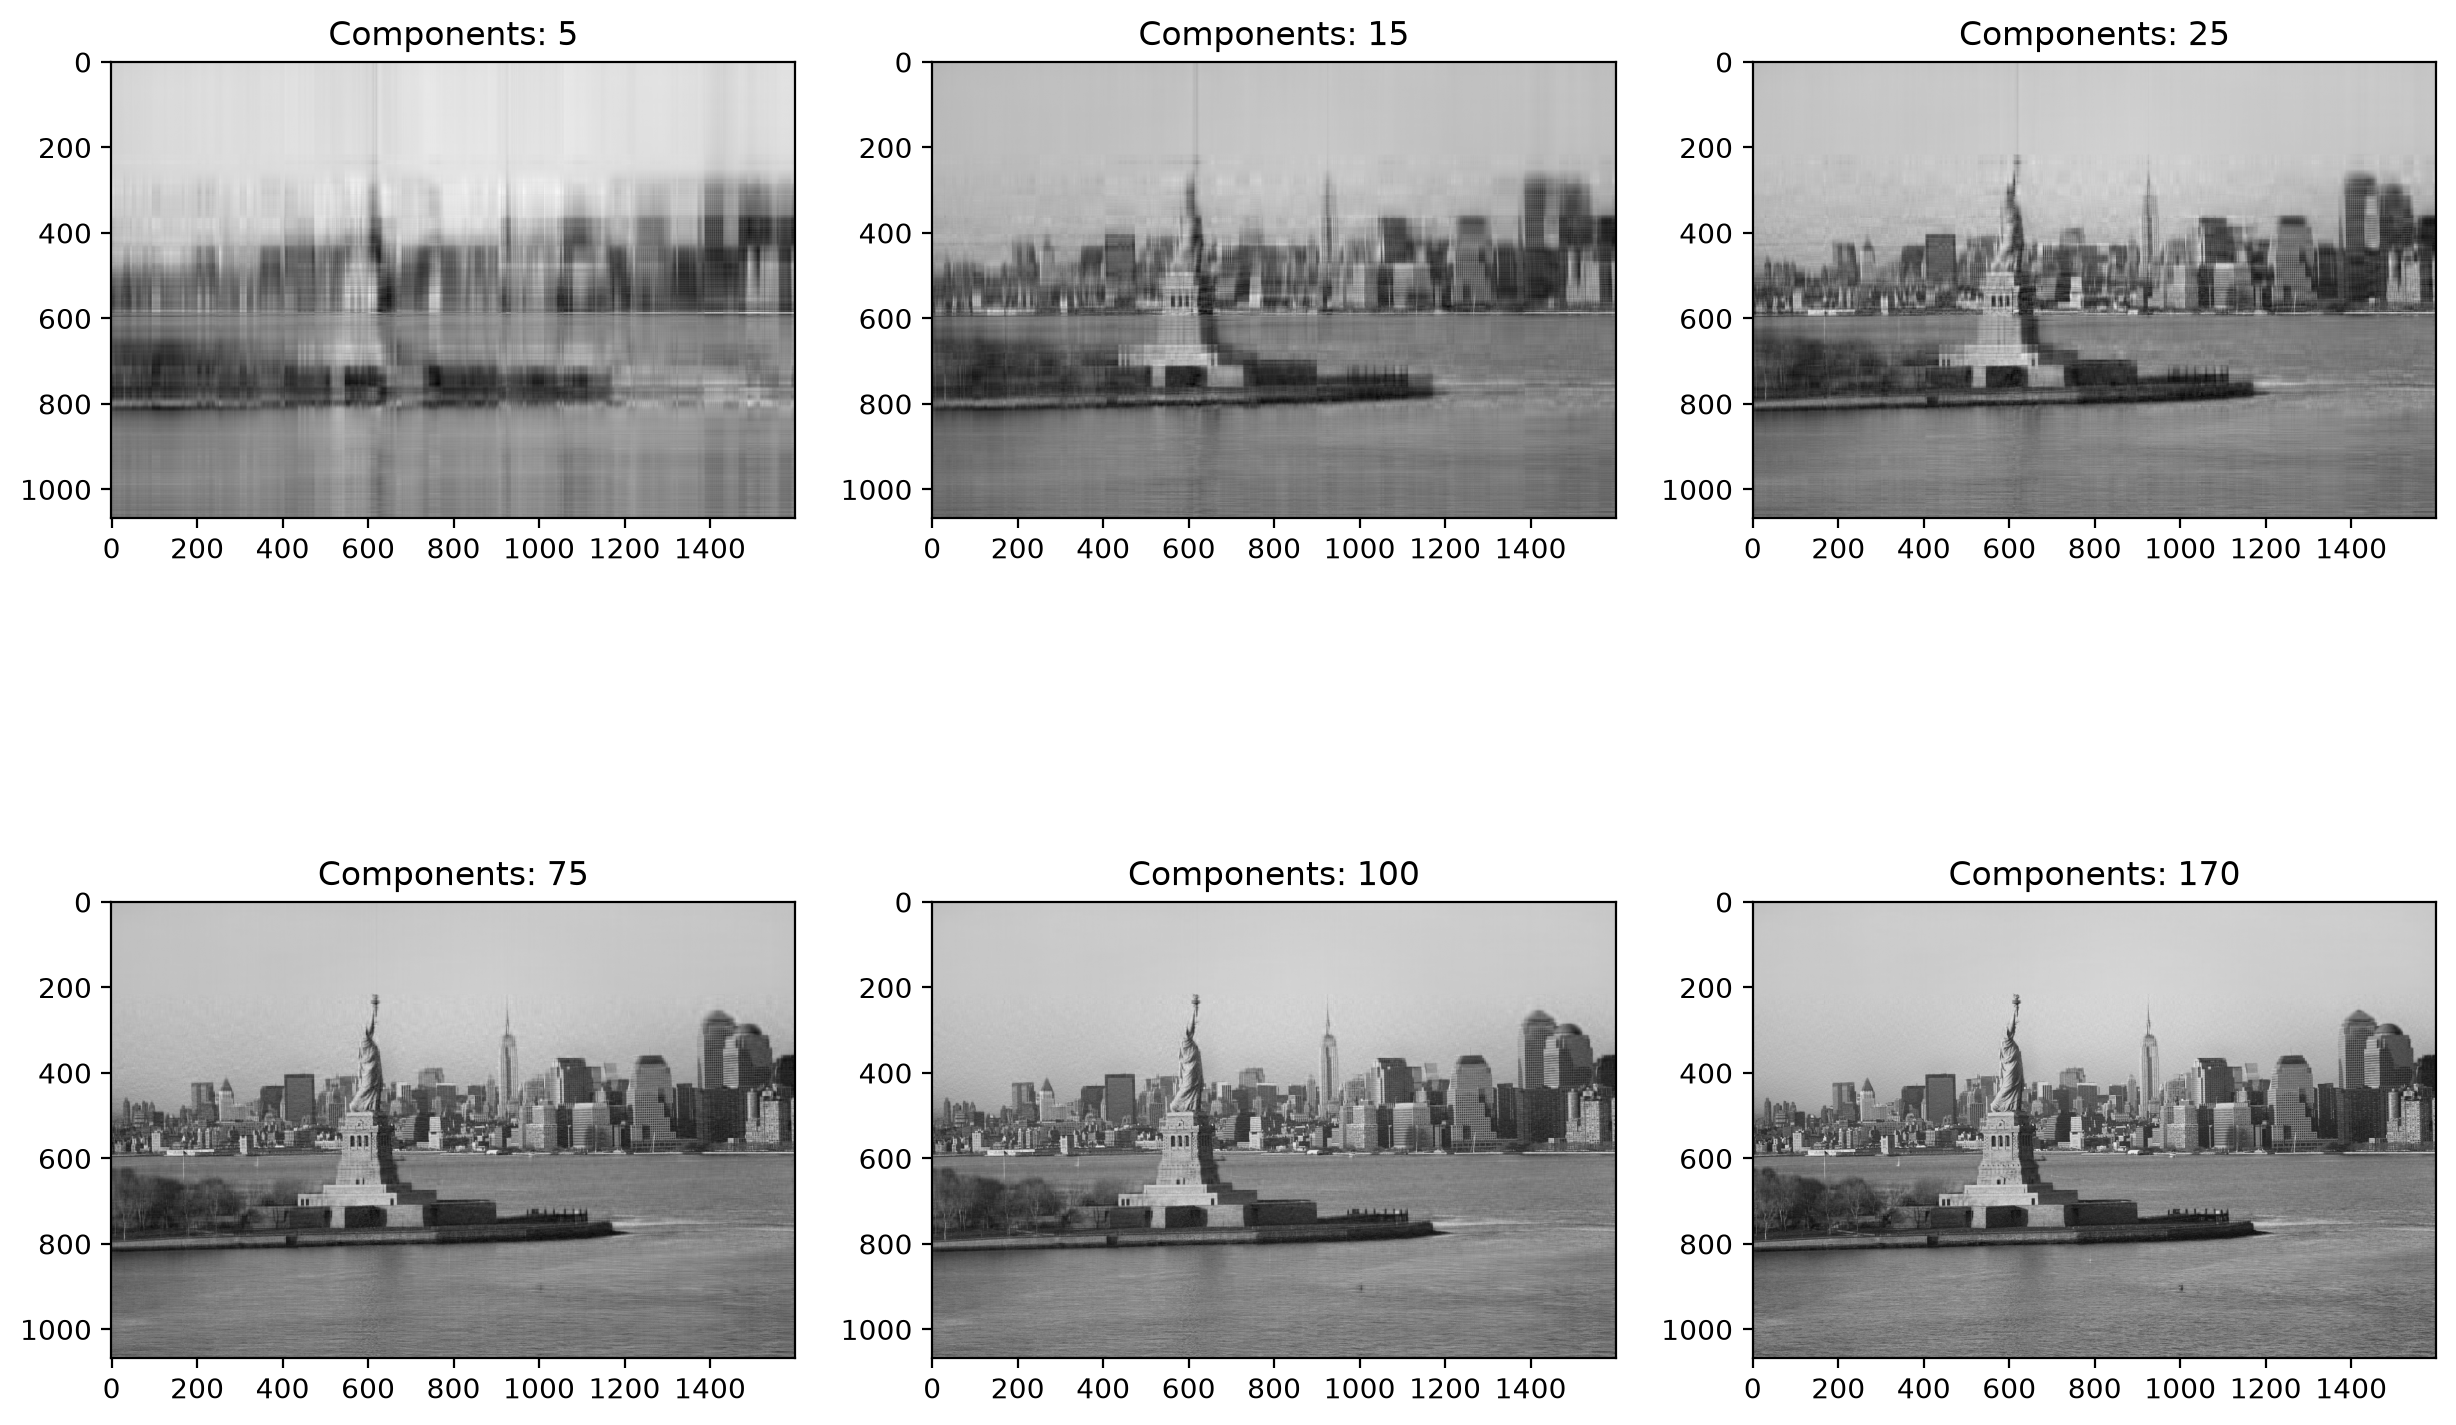

In [ ]:
def task2():

    # Part 1
    image_raw = imread("photo.jpg")
    print(image_raw.shape)

    plt.title("Original image")
    plt.imshow(image_raw)
    plt.show()

    # Part 2
    image_sum = image_raw.sum(axis=2)
    print(image_sum.shape)
    image_bw = image_sum/image_sum.max()
    print(image_bw.max())

    plt.title("Our black-white version of image")
    plt.imshow(image_bw, cmap="gray")
    plt.show()

    # Part 3
    pca = PCA()
    pca.fit(image_bw)

    cumulative_variance = np.cumsum(pca.explained_variance_ratio_) * 100

    n_components = np.argmax(cumulative_variance >= 95) + 1
    print(f"Number of components for the 95% variance {n_components}")

    plt.plot(cumulative_variance)
    plt.axhline(y=95, color="red", linestyle="--")
    plt.axvline(x=n_components, color="black", linestyle="--")
    plt.title("Cumulative Explained Variance by the components")
    plt.xlabel("Principal components")
    plt.ylabel("Cumulative Explained Variance")
    plt.show()

    pca_95 = PCA(n_components=n_components)
    image_reduced = pca_95.fit_transform(image_bw)
    image_reconstructed = pca_95.inverse_transform(image_reduced)

    plt.title("Reconstructed image")
    plt.imshow(image_reconstructed, cmap="gray")
    plt.show()

    # Part 4
    components = [5, 15, 25, 75, 100, 170]
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    for ax, n_comp in zip(axes.ravel(), components):
        pca_k = PCA(n_components=n_comp)

        reduced = pca_k.fit_transform(image_bw)
        reconstructed = pca_k.inverse_transform(reduced)

        ax.imshow(reconstructed, cmap="gray")
        ax.set_title(f"Components: {n_comp}")

    plt.show()
task2()

## Task 3: Using Diagonalization, Eigenvalues and Eigenvectors in Cryptography
In this task I had to create two functions to encrypt and decrypt messages using diagonalization and eigenvectors with eigenvalues. First function I copied straight from the lab file, but I also had to understand how this code works to create a decryptor. So, to create it, I had to find inverted matrix of key to get our message matrix as m = K_inv * c. And since K = P * D * P_inv, K_inv = P * D_inv * P_inv, so basically we have to find D_inv. And since it's diagonal, we can simply write inverted eigenvalue for each diagonal index. Combining all formulas in, we get the codes and get decrypted our message. After that I created small test for our encryption and decryption. Everything was fine.

In [5]:
def encrypt_message(message, key_matrix):

    message_vector = np.array([ord(char) for char in message])
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)
    diagonalized_key_matrix = eigenvectors @ np.diag(eigenvalues) @ np.linalg.inv(eigenvectors)
    encrypted_vector = np.dot(diagonalized_key_matrix, message_vector)

    return encrypted_vector

def decrypt_message(encrypted_vector, key_matrix):
    eigenvalues, eigenvectors = np.linalg.eig(key_matrix)

    inv_diagonal = np.diag(1.0 / eigenvalues)

    inv_key_matrix = eigenvectors @ inv_diagonal @ np.linalg.inv(eigenvectors)

    decrypted_vector = inv_key_matrix @ encrypted_vector

    codes = np.round(np.real(decrypted_vector)).astype(int)

    message = "".join([chr(code) for code in codes])
    
    return message

def task3(message="Hello, World!"):
    
    np.random.seed(67)
    key_matrix = np.random.randint(0, 256, (len(message), len(message)))

    encrypted = encrypt_message(message, key_matrix)
    decrypted = decrypt_message(encrypted, key_matrix)

    print("Original")
    print(message)

    print("\nEncrypted")
    print(encrypted)

    print("\nDecrypted")
    print(decrypted)

    print('All good ✅' if message == decrypted else 'Bad ❌')

task3()

Original
Hello, World!

Encrypted
[111379.-5.83460833e-12j 130898.-1.00520747e-11j 142707.-6.51770284e-13j
 167263.-3.71600620e-12j 173997.-2.10042257e-11j 149378.-1.16465139e-11j
 111703.-5.45600924e-12j 104790.-1.95509492e-12j 126939.-7.36058384e-12j
 157033.-2.23406291e-11j 164471.-9.99467321e-12j 124161.-9.55052433e-12j
 130216.-1.57952633e-11j]

Decrypted
Hello, World!
All good ✅
